In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## t-sne

**Figure 1(a): t-SNE embedding of the penultimate-layer features of a ResNet-34 trained on CIFAR-10, for 1,000 CIFAR-10 test samples.** Each color is one of the 10 classes, 100 samples each. All 10 classes form separate clusters, consistent with class-conditional Gaussian features.

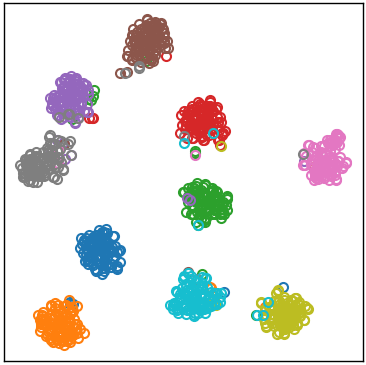

In [2]:
with open("../t-sne.json") as f:
    embedding = json.load(f)

# ten classes need more colors than the design's six series colors
PALETTE = plt.get_cmap("tab10").colors

fig, ax = plt.subplots(figsize=(5.5 / 3, 2))
for i in range(10):
    points = embedding[f"class_{i + 1}"]
    ax.plot(points["x"], points["y"], "o", color=PALETTE[i], markerfacecolor="none", linestyle="none",
            label=f"Class {i + 1}")

ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)

fit_height(fig, ax, aspect=1.0)
fig.savefig("t-sne.pdf")
fig.savefig("t-sne.png")
plt.show()